# 13 — Effective CLP resolution for source attribution

Using the already-computed dense curves from Qwen3-0.6B and GPT-2, test how many logarithmically spaced context-length measurements are needed for GPT-vs-Claude attribution.

\[
m\in\{1,2,3,4,6,8,16,32,64,128,249\}.
\]

For \(m=1\), use \(L_{256}\). For \(m>1\), choose points approximately uniformly in \(\log k\) between 8 and 256. \(m=249\) is the full dense curve \(L_8,\ldots,L_{256}\).

Interpret sparse > dense as improved statistical efficiency, not as sparse measurements containing information absent from the dense curve.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

cwd=Path.cwd().resolve()
ROOT=cwd.parent if cwd.name=="experiments" else cwd
RESULTS=ROOT/"results"
FIGURES=ROOT/"figures"
FIGURES.mkdir(parents=True,exist_ok=True)

QWEN_PATH=RESULTS/"cifka_dense_clp_qwen06b.parquet"
GPT2_PATH=RESULTS/"cifka_dense_clp_gpt2.parquet"

assert QWEN_PATH.exists(),QWEN_PATH
assert GPT2_PATH.exists(),GPT2_PATH


In [2]:
MIN_K,MAX_K=8,256
M_GRID=[1,2,3,4,6,8,16,32,64,128,249]
DENSE_COLS=[f"L_{k}" for k in range(MIN_K,MAX_K+1)]

def log_grid(m):
    if m==1:
        return [256]
    if m==249:
        return list(range(8,257))

    ideal=np.geomspace(8,256,m)
    chosen=[]
    unused=set(range(8,257))

    for z in ideal:
        k=min(unused,key=lambda q:(abs(np.log(q)-np.log(z)),q))
        chosen.append(k)
        unused.remove(k)

    chosen=sorted(chosen)
    if chosen[0]!=8:
        chosen[0]=8
    if chosen[-1]!=256:
        chosen[-1]=256

    # Repair any duplicate introduced by forcing endpoints.
    while len(set(chosen))<m:
        used=set(chosen)
        candidates=[q for q in range(8,257) if q not in used]
        q=min(candidates,key=lambda q:min(abs(np.log(q)-np.log(z)) for z in ideal))
        chosen.append(q)
        chosen=sorted(chosen)

    assert len(chosen)==m and len(set(chosen))==m
    return chosen

GRIDS={m:log_grid(m) for m in M_GRID}

for m,ks in GRIDS.items():
    p=ks if len(ks)<=12 else ks[:5]+["..."]+ks[-5:]
    print(m,p)


1 [256]
2 [8, 256]
3 [8, 45, 256]
4 [8, 25, 81, 256]
6 [8, 16, 32, 64, 128, 256]
8 [8, 13, 22, 35, 58, 95, 156, 256]
16 [8, 10, 13, 16, 20, '...', 102, 128, 161, 203, 256]
32 [8, 9, 10, 11, 13, '...', 164, 183, 205, 229, 256]
64 [8, 9, 10, 11, 12, '...', 205, 217, 229, 242, 256]
128 [8, 9, 10, 11, 12, '...', 230, 236, 242, 249, 256]
249 [8, 9, 10, 11, 12, '...', 252, 253, 254, 255, 256]


In [3]:
def prepare(path,scorer):
    df=pd.read_parquet(path).copy()
    df=df.dropna(subset=DENSE_COLS)
    s=df.groupby("pair_id")["generator"].agg(["size","nunique"])
    ok=s.index[(s["size"]==2)&(s["nunique"]==2)]
    df=df[df["pair_id"].isin(ok)].copy()
    df["label"]=(df["generator"]=="claude").astype(int)
    df["scorer"]=scorer
    return df

qwen=prepare(QWEN_PATH,"Qwen3-0.6B")
gpt2=prepare(GPT2_PATH,"GPT-2")

for name,df in [("Qwen3-0.6B",qwen),("GPT-2",gpt2)]:
    print(name,"pairs",df["pair_id"].nunique(),"docs",len(df))
    display(df.groupby(["domain","generator"]).size())


Qwen3-0.6B pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

GPT-2 pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

## Nested grouped evaluation

Each resolution independently selects logistic-regression regularization inside the training split, so DenseCLP is not unfairly penalized by a fixed regularization constant.


In [4]:
C_GRID=[1e-3,1e-2,1e-1,1.0,10.0]

def clf(C):
    return Pipeline([
        ("scale",StandardScaler()),
        ("clf",LogisticRegression(
            C=C,class_weight="balanced",solver="lbfgs",
            max_iter=5000,random_state=0
        ))
    ])

def choose_C(tr,cols):
    X=tr[cols]
    y=tr["label"].to_numpy()
    g=tr["pair_id"].to_numpy()
    cv=GroupKFold(n_splits=min(5,tr["pair_id"].nunique()))
    vals=[]

    for C in C_GRID:
        auc=[]
        for ti,vi in cv.split(X,y,groups=g):
            m=clf(C)
            m.fit(X.iloc[ti],y[ti])
            p=m.predict_proba(X.iloc[vi])[:,1]
            auc.append(roc_auc_score(y[vi],p))
        vals.append((np.mean(auc),C))

    vals.sort(key=lambda z:(-z[0],z[1]))
    return vals[0][1]

def eval_curve(df,scorer):
    ids=np.array(sorted(df["pair_id"].unique()))
    rows=[]

    for seed in range(20):
        rng=np.random.RandomState(seed)
        perm=rng.permutation(len(ids))
        cut=int(.8*len(ids))
        tr_ids=set(ids[perm[:cut]])
        te_ids=set(ids[perm[cut:]])
        tr=df[df["pair_id"].isin(tr_ids)]
        te=df[df["pair_id"].isin(te_ids)]

        for m,ks in GRIDS.items():
            cols=[f"L_{k}" for k in ks]
            C=choose_C(tr,cols)
            model=clf(C)
            model.fit(tr[cols],tr["label"])
            p=model.predict_proba(te[cols])[:,1]
            rows.append({
                "scorer":scorer,"seed":seed,"m":m,
                "ks":",".join(map(str,ks)),
                "best_C":C,
                "auroc":roc_auc_score(te["label"],p)
            })
    return pd.DataFrame(rows)

resolution=pd.concat([
    eval_curve(qwen,"Qwen3-0.6B"),
    eval_curve(gpt2,"GPT-2"),
],ignore_index=True)

resolution.to_csv(RESULTS/"context_resolution_curve_splits.csv",index=False)

display(resolution.groupby(["m","scorer"])["auroc"].mean().unstack())


scorer,GPT-2,Qwen3-0.6B
m,,
1,0.745444,0.848167
2,0.739000,0.852000
3,0.746889,0.843889
4,0.731556,0.850444
6,0.744167,0.866722
8,0.740333,0.855278
16,0.748889,0.858722
32,0.754500,0.854222
64,0.751833,0.854444


In [5]:
summary=[]

for scorer,sub in resolution.groupby("scorer"):
    means=sub.groupby("m")["auroc"].mean()
    dense=means.loc[249]

    for m in M_GRID:
        auc=means.loc[m]
        summary.append({
            "scorer":scorer,
            "m":m,
            "mean_auroc":auc,
            "absolute_gap_to_dense":dense-auc,
            "above_chance_retained_fraction":(auc-.5)/(dense-.5)
        })

summary=pd.DataFrame(summary)
summary.to_csv(RESULTS/"context_resolution_curve_summary.csv",index=False)
display(summary)

for scorer in summary["scorer"].unique():
    s=summary[summary["scorer"]==scorer].copy()
    print("\n",scorer)
    best=s.loc[s["mean_auroc"].idxmax()]
    print("best m:",int(best.m),"AUROC:",best.mean_auroc)

    for threshold in [.95,.975,.99]:
        ok=s[s["above_chance_retained_fraction"]>=threshold].sort_values("m")
        if len(ok):
            r=ok.iloc[0]
            print(f"smallest m >= {threshold:.1%} retention:",int(r.m))
        else:
            print(f"no m reaches {threshold:.1%}")


,scorer,m,mean_auroc,absolute_gap_to_dense,above_chance_retained_fraction
0,GPT-2,1,0.745444,0.005778,0.977001
1,GPT-2,2,0.739000,0.012222,0.951349
2,GPT-2,3,0.746889,0.004333,0.982751
3,GPT-2,4,0.731556,0.019667,0.921716
4,GPT-2,6,0.744167,0.007056,0.971915
5,GPT-2,8,0.740333,0.010889,0.956656
6,GPT-2,16,0.748889,0.002333,0.990712
7,GPT-2,32,0.754500,-0.003278,1.013047
8,GPT-2,64,0.751833,-0.000611,1.002433
9,GPT-2,128,0.750333,0.000889,0.996462



 GPT-2
best m: 32 AUROC: 0.7545
smallest m >= 95.0% retention: 1
smallest m >= 97.5% retention: 1
smallest m >= 99.0% retention: 16

 Qwen3-0.6B
best m: 6 AUROC: 0.8667222222222222
smallest m >= 95.0% retention: 1
smallest m >= 97.5% retention: 1
smallest m >= 99.0% retention: 1


In [6]:
delta_rows=[]

for scorer,sub in resolution.groupby("scorer"):
    w=sub.pivot(index="seed",columns="m",values="auroc")
    for m in M_GRID[:-1]:
        d=w[m]-w[249]
        delta_rows.append({
            "scorer":scorer,"m":m,
            "mean_sparse_minus_dense":d.mean(),
            "median_sparse_minus_dense":d.median(),
            "q25":d.quantile(.25),"q75":d.quantile(.75),
            "min":d.min(),"max":d.max(),
            "sparse_better":int((d>0).sum()),"n":len(d)
        })

deltas=pd.DataFrame(delta_rows)
deltas.to_csv(RESULTS/"context_resolution_curve_deltas.csv",index=False)
display(deltas)


,scorer,m,mean_sparse_minus_dense,median_sparse_minus_dense,q25,q75,min,max,sparse_better,n
0,GPT-2,1,-0.005778,-1.055556e-02,-0.028889,0.016944,-0.052222,0.060000,9,20
1,GPT-2,2,-0.012222,-1.833333e-02,-0.034444,0.014722,-0.060000,0.030000,7,20
2,GPT-2,3,-0.004333,-2.222222e-03,-0.019167,0.004722,-0.037778,0.042222,9,20
3,GPT-2,4,-0.019667,-1.722222e-02,-0.033611,-0.009444,-0.055556,0.026667,3,20
4,GPT-2,6,-0.007056,-7.777778e-03,-0.023611,0.002778,-0.033333,0.044444,6,20
5,GPT-2,8,-0.010889,-1.444444e-02,-0.020278,-0.006389,-0.048889,0.044444,4,20
6,GPT-2,16,-0.002333,-5.555556e-03,-0.009167,0.001111,-0.030000,0.050000,7,20
7,GPT-2,32,0.003278,1.666667e-03,-0.014722,0.015556,-0.021111,0.056667,12,20
8,GPT-2,64,0.000611,5.555556e-04,-0.006944,0.010556,-0.060000,0.034444,10,20
9,GPT-2,128,-0.000889,5.555556e-04,-0.006667,0.005833,-0.038889,0.031111,10,20


## Held-out-domain resolution curves


In [7]:
LABELS={"essay":"Essay","reuter":"Reuters","wp":"Wikipedia"}

def domain_curve(df,scorer):
    rows=[]
    for heldout in ["essay","reuter","wp"]:
        tr=df[df["domain"]!=heldout]
        te=df[df["domain"]==heldout]

        for m,ks in GRIDS.items():
            cols=[f"L_{k}" for k in ks]
            C=choose_C(tr,cols)
            model=clf(C)
            model.fit(tr[cols],tr["label"])
            p=model.predict_proba(te[cols])[:,1]
            rows.append({
                "scorer":scorer,
                "heldout_domain":heldout,
                "heldout_domain_label":LABELS[heldout],
                "m":m,
                "auroc":roc_auc_score(te["label"],p),
                "best_C":C
            })
    return pd.DataFrame(rows)

transfer=pd.concat([
    domain_curve(qwen,"Qwen3-0.6B"),
    domain_curve(gpt2,"GPT-2")
],ignore_index=True)

transfer.to_csv(RESULTS/"context_resolution_curve_cross_domain.csv",index=False)

display(
    transfer.pivot_table(
        index=["scorer","heldout_domain_label"],
        columns="m",values="auroc"
    )
)


m                                     1         2         3         4    \
scorer     heldout_domain_label                                           
GPT-2      Essay                 0.759452  0.694707  0.757089  0.684783   
           Reuters               0.901291  0.895877  0.865056  0.905456   
           Wikipedia             0.665513  0.666667  0.670896  0.659362   
Qwen3-0.6B Essay                 0.905009  0.877127  0.899338  0.866257   
           Reuters               0.922949  0.925031  0.925031  0.910037   
           Wikipedia             0.871972  0.851980  0.854287  0.849673   

m                                     6         8         16        32   \
scorer     heldout_domain_label                                           
GPT-2      Essay                 0.756616  0.768431  0.737713  0.771267   
           Reuters               0.872553  0.872970  0.855893  0.859642   
           Wikipedia             0.673203  0.681276  0.674356  0.681276   
Qwen3-0.6B Essay                 0.915406  0.899811  0.880435  0.911626   
           Reuters               0.904207  0.920866  0.912120  0.907955   
           Wikipedia             0.857747  0.848135  0.861976  0.859669   

m                                     64        128       249  
scorer     heldout_domain_label                                
GPT-2      Essay                 0.781664  0.786389  0.788280  
           Reuters               0.842982  0.838401  0.842566  
           Wikipedia             0.690504  0.693195  0.677047  
Qwen3-0.6B Essay                 0.902647  0.896975  0.883270  
           Reuters               0.917534  0.906706  0.889629  
           Wikipedia             0.856978  0.875433  0.877739

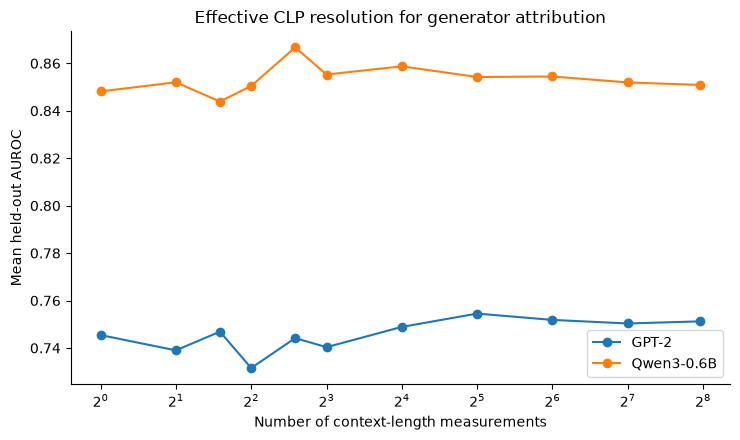

In [8]:
fig,ax=plt.subplots(figsize=(7.5,4.5))

for scorer,s in summary.groupby("scorer"):
    s=s.sort_values("m")
    ax.plot(s["m"],s["mean_auroc"],marker="o",label=scorer)

ax.set_xscale("log",base=2)
ax.set_xlabel("Number of context-length measurements")
ax.set_ylabel("Mean held-out AUROC")
ax.set_title("Effective CLP resolution for generator attribution")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"context_resolution_curve.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"context_resolution_curve.png",dpi=200,bbox_inches="tight")
plt.show()


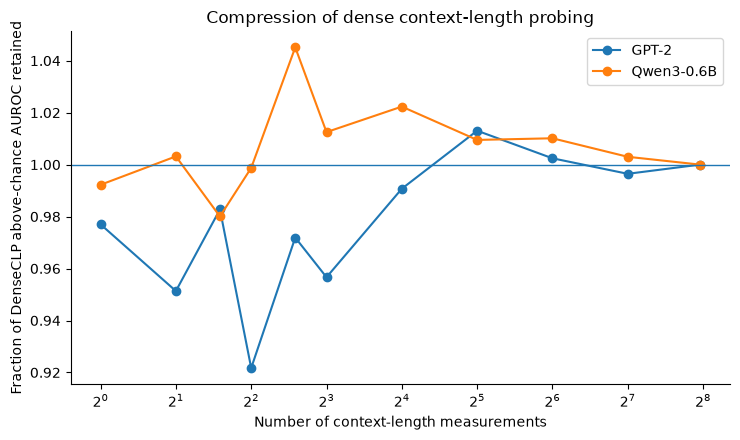

In [9]:
fig,ax=plt.subplots(figsize=(7.5,4.5))

for scorer,s in summary.groupby("scorer"):
    s=s.sort_values("m")
    ax.plot(
        s["m"],s["above_chance_retained_fraction"],
        marker="o",label=scorer
    )

ax.axhline(1.0,linewidth=1)
ax.set_xscale("log",base=2)
ax.set_xlabel("Number of context-length measurements")
ax.set_ylabel("Fraction of DenseCLP above-chance AUROC retained")
ax.set_title("Compression of dense context-length probing")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"context_resolution_retention.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"context_resolution_retention.png",dpi=200,bbox_inches="tight")
plt.show()


## Reading the result

The robust claim to look for is not that one fixed sparse grid wins for every scorer.

The stronger cross-scorer question is whether high retained performance is reached at very low \(m\). If so:

> The source-attribution value of dense context-length probing saturates at low measurement resolution, although the precise optimal sparse resolution can be scorer-dependent.

Particularly report the smallest \(m\) reaching 95%, 97.5%, and 99% of DenseCLP's above-chance AUROC, the peak-resolution \(m\), and held-out-domain behavior.
